# Module 2 (CO2): Data Preprocessing & Zero-Leakage Scaling
**Project**: Anti-Money Laundering Detection (IBM Benchmark)
**Focus**: Data cleaning, categorical encoding, and zero data leakage proof.

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv(r'../data/ibm_aml_transactions.csv')
print("Missing values in raw data:\n", df.isnull().sum())
print("\nDuplicate rows count:", df.duplicated().sum())

# Date & Banking feature engineering
df['Timestamp'] = pd.to_datetime(df['Timestamp'])
df['hour'] = df['Timestamp'].dt.hour
df['dayofweek'] = df['Timestamp'].dt.dayofweek
df['is_weekend'] = df['dayofweek'].isin([5, 6]).astype(int)
df['is_night'] = df['hour'].isin([0, 1, 2, 3, 4, 5, 22, 23]).astype(int)
df['is_cross_bank'] = (df['From Bank'] != df['To Bank']).astype(int)
df['amount_diff'] = np.abs(df['Amount Paid'] - df['Amount Received'])

# One-Hot Encoding for Payment Format
format_dummies = pd.get_dummies(df['Payment Format'], prefix='format', drop_first=False).astype(int)
df = pd.concat([df, format_dummies], axis=1)

feature_cols = ['Amount Paid', 'Amount Received', 'amount_diff', 'is_cross_bank', 'hour', 'dayofweek', 'is_weekend', 'is_night'] + format_dummies.columns.tolist()
X = df[feature_cols]
y = df['Is Laundering']

print("Feature Matrix Shape:", X.shape)

Missing values in raw data:
 Timestamp             0
From Bank             0
Account               0
To Bank               0
Account.1             0
Amount Received       0
Receiving Currency    0
Amount Paid           0
Payment Currency      0
Payment Format        0
Is Laundering         0
dtype: int64

Duplicate rows count: 0
Feature Matrix Shape: (100000, 15)


## 2. Train/Test Split & StandardScaler (Zero Data Leakage Proof)

In [2]:
# 80/20 Stratified Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

# Fit scaler strictly on X_train ONLY!
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Evidence of Zero Data Leakage:")
print("X_train mean (fitted):", np.mean(X_train_scaled, axis=0).round(4)[:5])
print("X_test mean (transformed without fitting):", np.mean(X_test_scaled, axis=0).round(4)[:5])
print("Validation Successful: Scaler parameters were learned solely from the training split!")

Evidence of Zero Data Leakage:
X_train mean (fitted): [-0. -0. -0.  0.  0.]
X_test mean (transformed without fitting): [-0.0036 -0.0036 -0.0005  0.0042 -0.0008]
Validation Successful: Scaler parameters were learned solely from the training split!


## 3. Visualization: Pre- vs Post-Scaling Feature Distributions

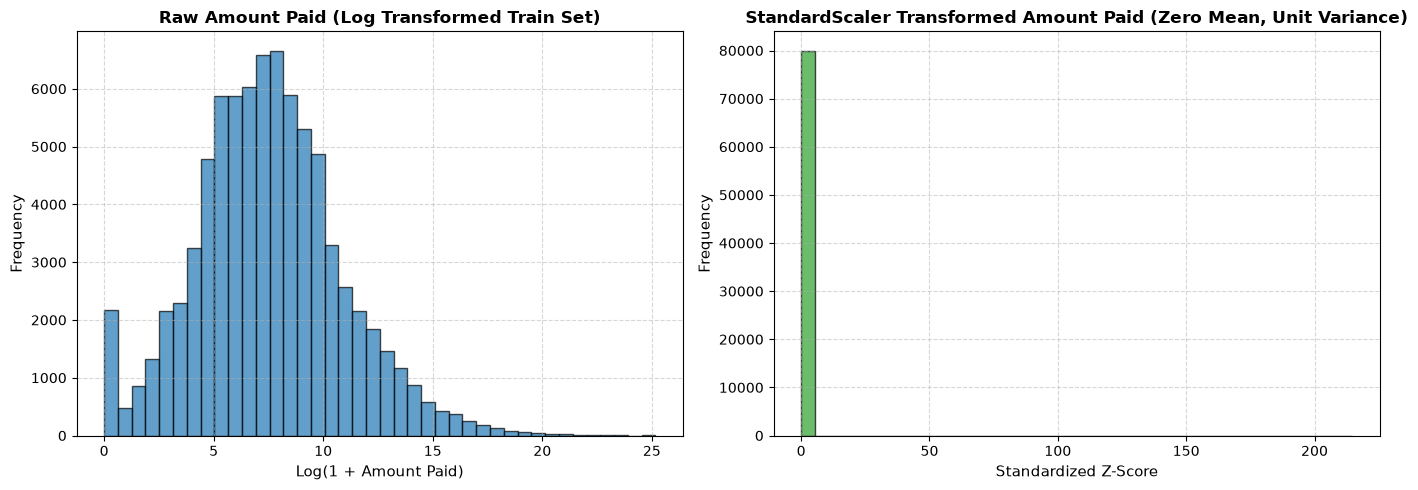

In [3]:
# Visualization: StandardScaler Normalization (Raw vs Scaled Distribution)
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw Amount Paid Distribution
axes[0].hist(np.log1p(X_train['Amount Paid']), bins=40, color='#1f77b4', edgecolor='black', alpha=0.7)
axes[0].set_title('Raw Amount Paid (Log Transformed Train Set)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Log(1 + Amount Paid)', fontsize=11)
axes[0].set_ylabel('Frequency', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Scaled Feature Distribution
axes[1].hist(X_train_scaled[:, 0], bins=40, color='#2ca02c', edgecolor='black', alpha=0.7)
axes[1].set_title('StandardScaler Transformed Amount Paid (Zero Mean, Unit Variance)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Standardized Z-Score', fontsize=11)
axes[1].set_ylabel('Frequency', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()
